# 🪐 Planet Hunters — starter notebook
**ML Challenge Hack4Hack 2026 · Round 1**

This notebook loads the data, plots a few stars, builds simple statistics for every star, trains a gradient-boosting model and writes a valid `submission.csv`.

It is a **baseline**: it ignores periods, dip shapes, centroids and flares, so it scores low. Beating it is your job. It runs in about 2 minutes on a laptop with 8 GB RAM.

Put this notebook in the same folder as the data files (or change `DATA` below).

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

DATA = '.'   # folder with the .npy and .csv files
train_flux = np.load(f'{DATA}/train_flux.npy', mmap_mode='r')        # (18000, 1315) electrons/s, NaN = gap
train_cen  = np.load(f'{DATA}/train_centroid.npy', mmap_mode='r')    # (18000, 2, 1315) millipixels
test_flux  = np.load(f'{DATA}/test_flux.npy', mmap_mode='r')
train = pd.read_csv(f'{DATA}/train_stars.csv')
test  = pd.read_csv(f'{DATA}/test_stars.csv')
cad   = pd.read_csv(f'{DATA}/train_cadences.csv')
t = cad.time_btjd.values
print(train_flux.shape, test_flux.shape)
train.label.value_counts()

(18000, 1315) (7000, 1315)


label
quiet_star           3624
starspots            2882
eclipsing_binary     2247
planet               2145
pulsating_star       1973
flare_star           1804
instrument_glitch    1721
background_binary    1604
Name: count, dtype: int64

## Look at the data
One star of each label: relative brightness (top) and centroid column offset (bottom). Orange ticks mark momentum dumps (`quality & 1`).

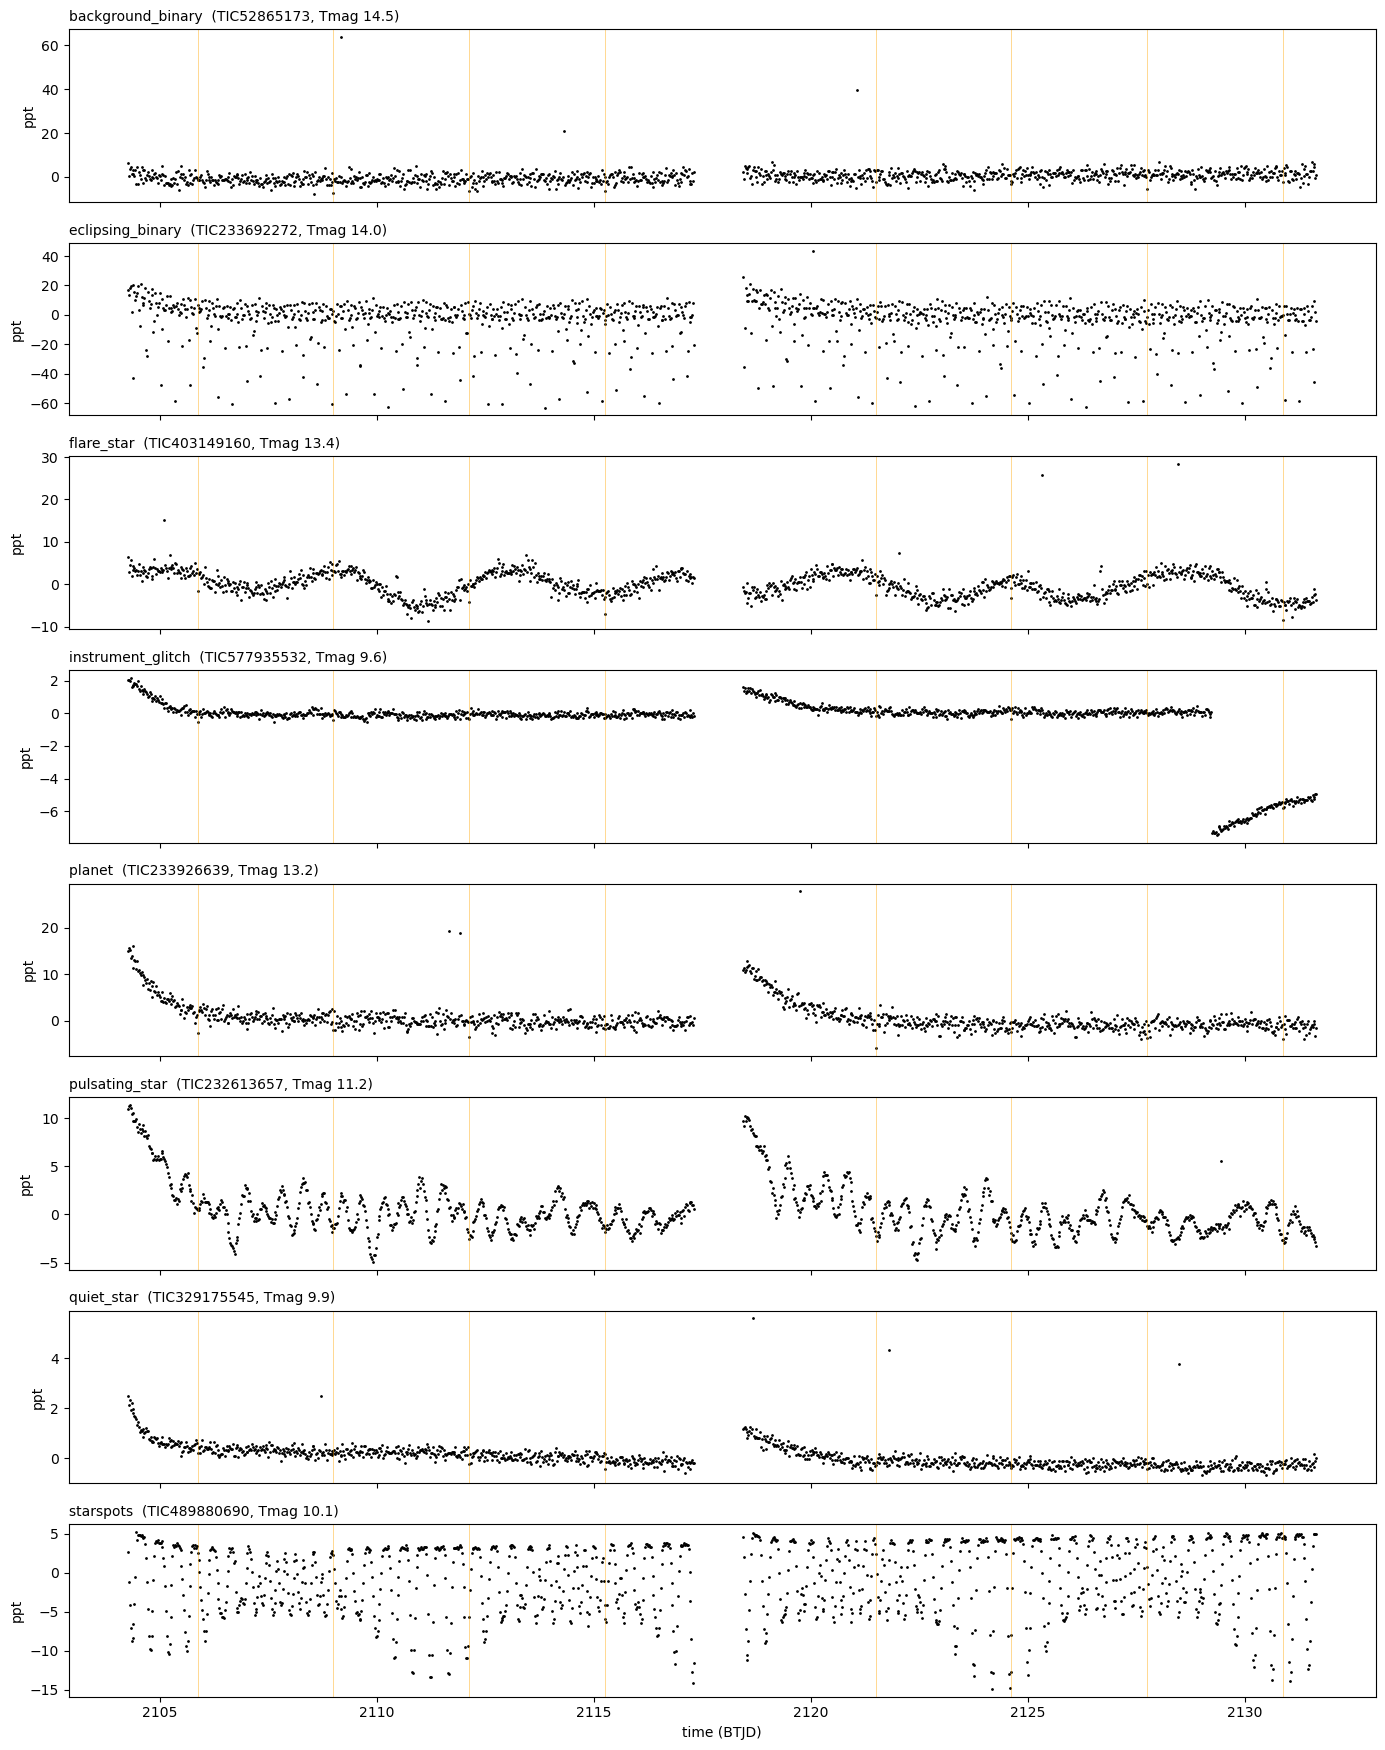

In [3]:
labels = sorted(train.label.unique())
fig, axes = plt.subplots(len(labels), 1, figsize=(14, 2.2 * len(labels)), sharex=True)
dumps = t[(cad.quality.values & 1) > 0]
for ax, lab in zip(axes, labels):
    i = train.index[train.label == lab][0]
    f = train_flux[i] / np.nanmedian(train_flux[i]) - 1
    ax.plot(t, f * 1e3, '.', ms=2, color='k')
    for d in dumps: ax.axvline(d, color='orange', lw=0.5, alpha=0.6)
    ax.set_ylabel('ppt'); ax.set_title(f'{lab}  ({train.id[i]}, Tmag {train.tmag[i]:.1f})', fontsize=10, loc='left')
axes[-1].set_xlabel('time (BTJD)'); plt.tight_layout(); plt.show()

## Simple features
Normalise each star by its median, then compute spread, extremes, skewness and percentiles. Add the star properties from the CSV.

In [4]:
def simple_features(flux, stars, batch=2000):
    out = []
    for s in range(0, len(flux), batch):
        f = np.asarray(flux[s:s + batch], np.float64)
        f = f / np.nanmedian(f, axis=1, keepdims=True) - 1
        out.append(pd.DataFrame({
            'std': np.nanstd(f, 1),
            'mad': np.nanmedian(np.abs(f - np.nanmedian(f, 1, keepdims=True)), 1),
            'min': np.nanmin(f, 1), 'max': np.nanmax(f, 1),
            'skew': stats.skew(f, 1, nan_policy='omit'), 'kurt': stats.kurtosis(f, 1, nan_policy='omit'),
            **{f'p{q}': np.nanpercentile(f, q, 1) for q in (1, 5, 25, 75, 95, 99)},
        }))
    X = pd.concat(out, ignore_index=True)
    return pd.concat([X, stars[['tmag', 'teff', 'logg', 'radius', 'contamination']].reset_index(drop=True)], axis=1)

X = simple_features(train_flux, train)
X_test = simple_features(test_flux, test)
X.head()

,std,mad,min,max,skew,kurt,p1,p5,p25,p75,p95,p99,tmag,teff,logg,radius,contamination
0,0.000448,0.000235,-0.000681,0.005590,3.613154,30.039177,-0.000522,-0.000423,-0.000210,0.000267,0.000736,0.001600,9.894,3020,4.93,0.24,0.172
1,0.004540,0.003619,-0.014857,0.005219,-0.631655,-0.430790,-0.012814,-0.009150,-0.004217,0.003315,0.004609,0.004971,10.088,6390,4.46,0.96,0.013
2,0.015176,0.004691,-0.063056,0.043606,-1.992292,4.204556,-0.059666,-0.041669,-0.004313,0.004907,0.010247,0.017222,13.970,5880,4.25,1.29,0.025
3,0.008930,0.003015,-0.042422,0.007684,-3.238277,11.136360,-0.041342,-0.019930,-0.002771,0.003564,0.005975,0.006626,11.544,4100,3.13,3.91,0.440
4,0.003020,0.002211,-0.008673,0.028297,1.077120,9.509242,-0.006066,-0.004769,-0.002276,0.002186,0.004002,0.005534,13.357,7950,4.10,1.27,0.103


## Train and validate
Hold out 20% of the training stars to estimate the macro-F1 score. (The test set comes from a different sector, so expect your leaderboard score to be a bit different.)

In [5]:
X_tr, X_va, y_tr, y_va = train_test_split(X, train.label, test_size=0.2, stratify=train.label, random_state=42)
model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, class_weight='balanced', random_state=0)
model.fit(X_tr, y_tr)
print('validation macro-F1:', round(f1_score(y_va, model.predict(X_va), average='macro'), 4))

c:\Users\omkul\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\omkul\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\omkul\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\omkul\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\omkul\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

validation macro-F1: 0.4281


## Train on everything and write the submission

In [6]:
model.fit(X, train.label)
sub = pd.DataFrame({'id': test.id, 'label': model.predict(X_test)})
sub.to_csv('submission.csv', index=False)
sub.label.value_counts()

label
instrument_glitch    1884
pulsating_star       1324
flare_star           1041
quiet_star            635
starspots             573
background_binary     541
eclipsing_binary      540
planet                462
Name: count, dtype: int64

## Ideas to climb the leaderboard
- **Detrend**: subtract the median curve of all stars on the same `camera`/`ccd`, then remove slow variations with a median filter.
- **Search for transits**: run a Box Least Squares search (`astropy.timeseries.BoxLeastSquares`) and fold on the best period.
- **Vet the dip**: depth, duration, U vs V shape, odd vs even depth, a secondary eclipse at phase 0.5, and **the centroid shift during the dip**.
- **Ignore or use the flags**: momentum dumps (`quality & 1`) cause blips that are not transits.
- **Frequencies**: a periodogram tells spots (days) from pulsations (hours).
- **Flares**: bright outliers with a decaying tail vs single-point cosmic rays.
- **Deep learning**: a 1D CNN on detrended flux + folded flux + centroids.